# 1.消息类型
在LangChain中，发送给LLM的消息、LLM返回的消息都统一被封装为BaseMessage，它是Agent中基本的上下文单元。
在LangChain中，我们并不需要自己创建BaseMessage对象，LangChain已经把常见消息根据角色(Role)创建了
对应的BaseMessage的子类:

1. SystemMessage: role是system，代表系统消息，用于设定模型角色和交互背景
2. HumanMessage: role是user，代表用户输入的消息
3. AIMessage: role是assistant，代表LLM生成的响应，包含:文本、工具调用、元数据
4. ToolMessage: role是tool，代表工具调用时产生的结果

我们可以直接使用这些Messages类型来发送消息。

In [1]:
import os
from dotenv import load_dotenv
from langchain.agents import create_agent
from langchain.tools import tool
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage

# ================= 核心修复点：在此处加载环境变量 =================
# 强制指定绝对路径，让 create_agent 内部能顺利读到 DEEPSEEK_API_KEY
load_dotenv(dotenv_path=r"D:\Project\my_ai_project\WorkArea\.env", override=True)
# =================================================================

# 定义工具
@tool
def get_weather(location: str) -> str:
    """
    Get the weather in a given location.
    Args:
        location: city name or coordinates
    """
    return f"Current weather in {location} is sunny"

# 创建Agent (此时环境变量已加载，它就能自己找到了)
agent = create_agent(model="deepseek-chat", tools=[get_weather])

# 调用Agent，发送消息
response = agent.invoke({
    "messages":[
#        {"role":"system", "content":"你是一个热心的AI助手."},
#        {"role":"user", "content":"你好，我是刚哥."}, 
#        {"role":"assistant", "content":"你好，刚哥，很高兴认识你."},
#        {"role":"user", "content":"广州今天天气如何?"},
        # SystemMessage(content="你可以调用 get_weather 工具来获取天气信息."),
        SystemMessage("你可以调用 get_weather 工具来获取天气信息."),
        HumanMessage("你好，我是刚哥."),
        AIMessage("你好，刚哥，很高兴认识你."),
        HumanMessage("广州今天天气如何?")
    ]
})

# 打印 Agent 的完整返回（方便你观察消息流）

print(response)

{'messages': [SystemMessage(content='你可以调用 get_weather 工具来获取天气信息.', additional_kwargs={}, response_metadata={}, id='f6f742e8-c498-4312-bb22-382a8153fa72'), HumanMessage(content='你好，我是刚哥.', additional_kwargs={}, response_metadata={}, id='efefec80-33c5-481e-91cd-e82d467defa1'), AIMessage(content='你好，刚哥，很高兴认识你.', additional_kwargs={}, response_metadata={}, id='b3e32847-ac17-4047-b374-38ff1b7af7a5', tool_calls=[], invalid_tool_calls=[]), HumanMessage(content='广州今天天气如何?', additional_kwargs={}, response_metadata={}, id='b02627ef-e2b5-4b11-b6b7-a13390d7c191'), AIMessage(content='我来帮你查一下广州今天的天气。', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 45, 'prompt_tokens': 313, 'total_tokens': 358, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 128, 'image_tokens': None, 'text_tokens': None}, 'prompt_cache_hit_tokens': 128, 'prompt_cache_miss_tokens': 185}, 'model_provider': 'd

In [2]:
for message in response['messages']:
    message.pretty_print()

================================ System Message ================================

你可以调用 get_weather 工具来获取天气信息.
================================ Human Message =================================

你好，我是刚哥.
================================== Ai Message ==================================

你好，刚哥，很高兴认识你.
================================ Human Message =================================

广州今天天气如何?
================================== Ai Message ==================================

我来帮你查一下广州今天的天气。
Tool Calls:
  get_weather (call_00_XsoSy88TYzxfXQxBX97F1070)
 Call ID: call_00_XsoSy88TYzxfXQxBX97F1070
  Args:
    location: 广州
================================= Tool Message =================================
Name: get_weather

Current weather in 广州 is sunny
================================== Ai Message ==================================

刚哥，广州今天天气是晴天（sunny）☀️。如果需要更详细的温度、湿度等信息，或者想查询其他城市，随时告诉我。


# 2.多模态消息

之前我们都是向模型发送文本消息，但是LangChain也支持向模型发送多模态消息，比如图片、音频、视频、文本等。但前提是必须是多模态模型才支持。

一些支持多模态的模型有:

· qwen3.5-plus
· gpt-5-nano

我们以qwen3.5-plus为例，演示向模型发送图片消息

## 2.1.在线图片

首先，我们演示如何发送一个在线图片给模型，也就是指定模型的url地址。图片如下:
https://ts3.tc.mm.bing.net/th/id/OIP-C.YUmiTYnc4_RS1FBNeuIaKQHaE7?r=0&rs=1&pid=ImgDetMain&o=7&rm=3

In [58]:
from langchain.chat_models import init_chat_model
import os

model = init_chat_model(
    model="qwen3.7-plus", # 模型名称，这里可以自定义，我们用的是阿里的qwen-puls
    model_provider="openai", 
    # 如果是Langchain不支持的模型，需要指定模型提供者(虽然我们用的是阿里，但是阿里兼容openai，所以这里用openai)
    base_url = os.getenv("DASHSCOPE_BASE_URL"),
    api_key = os.getenv("DASHSCOPE_API_KEY")
)

In [59]:
agent = create_agent(model=model)

In [60]:
# 准备多模态
message = HumanMessage([
       {"type":"text", "text":"描述一下这张图片"},
       {"type":"image", "url":"https://ts3.tc.mm.bing.net/th/id/OIP-C.YUmiTYnc4_RS1FBNeuIaKQHaE7?r=0&rs=1&pid=ImgDetMain&o=7&rm=3"}
]
     
)

In [61]:
stream = agent.stream(
    {"messages":[message]},
    stream_mode = "messages")

for chunk, metadata in stream:
    if chunk.content:
        print(chunk.content, end="", flush=True)

这张图片展示了一幅宁静而美丽的自然风景画，描绘的是**日落（或日出）时分的湿地或沼泽景观**。以下是画面的详细描述：

1.  **核心元素与构图**：
    *   **木栈道**：画面正中央有一条蜿蜒的木制栈道，从前景一直延伸到远方。它像一条引导线，将观者的视线引向地平线上的太阳。
    *   **高大的松树**：在画面的左侧，矗立着一棵形态优美、枝繁叶茂的松树（看起来像马尾松）。它在逆光下呈现出深色的剪影，与右侧开阔的视野形成了平衡。
    *   **湿地植被**：周围是大片茂密的绿色草地，看起来像是典型的湿地环境。草丛高低错落，左下角还可以看到一汪积水，反射着天空的光亮。

2.  **光影与色彩**：
    *   **金色的阳光**：太阳正处于地平线附近（看起来像是日落时分），发出耀眼的光芒，形成了明显的星芒效果。阳光洒在草地上，给绿色的植被镀上了一层金黄色的光边，营造出温暖、辉煌的氛围。
    *   **天空**：天空呈现出从淡蓝色到金黄色的渐变，几缕淡淡的云彩横在空中，增加了画面的层次感。

3.  **整体氛围**：
    *   整张图片给人一种**宁静、祥和、生机勃勃**的感觉。暖色调的阳光与冷色调的阴影（如树下的暗部）形成了鲜明的对比，展现了大自然的壮丽与柔美。

此外，图片中央有一个淡淡的水印，显示“摄图网”，表明这是一张版权素材图片。

## 2.1.本地图片

首先，我们演示如何发送一个在线图片给模型，也就是指定模型的url地址。图片如下:
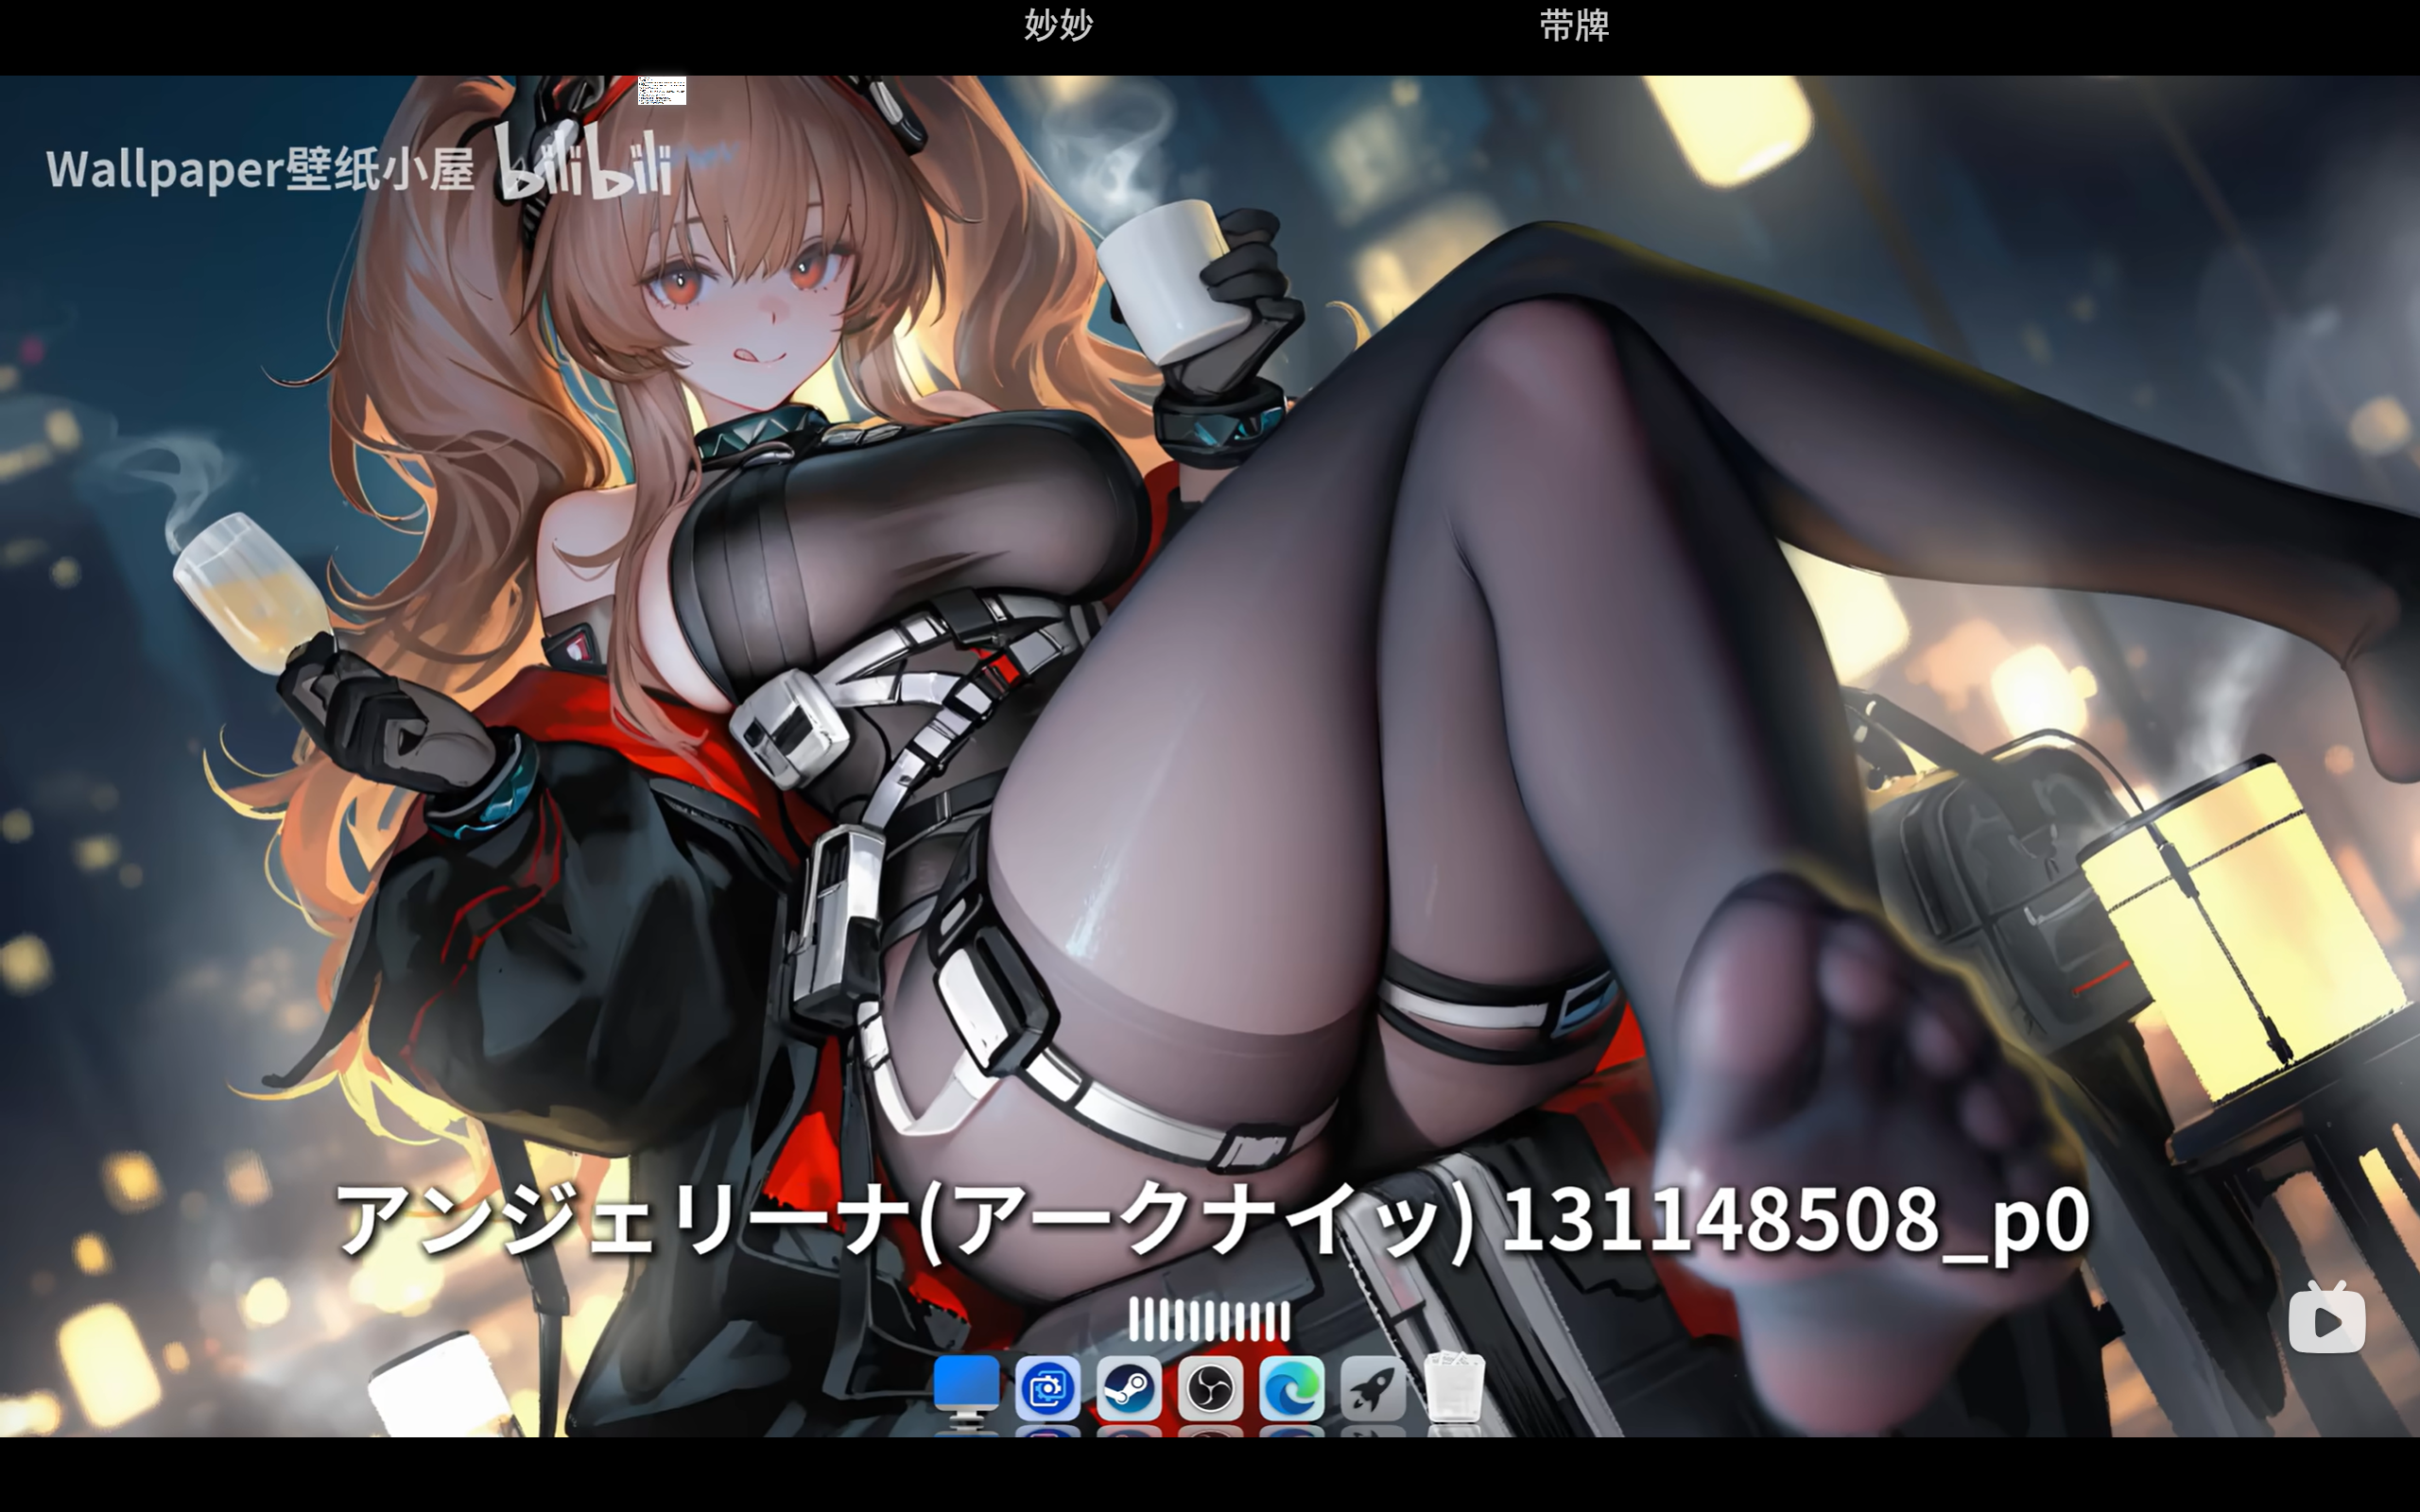

In [ ]:
import base64
import os
from dotenv import load_dotenv
from langchain_core.messages import HumanMessage

# 1. 加载环境变量
load_dotenv(dotenv_path=r"D:\Project\my_ai_project\WorkArea\.env", override=True)

# 2. 使用你刚找到的绝对路径（其实就是你想在本地识别图片的图片的绝对路径。注意前面加 r）
image_path = r"E:\我的电脑桌面\图图图\2.png"

# 3. 读取图片并转成 Base64
with open(image_path, "rb") as f:
    base64_image = base64.b64encode(f.read()).decode("utf-8")

# 4. 构造多模态消息

"""
message = {
    "role": "user",
    "content": [
        {"type": "text", "text": "描述一下这张图片"},# 你问的问题
        {"type": "image", "url": "Snipaste_2026-08-24_19-55-22.png"},
    ]
}
"""

message = HumanMessage([
    {"type": "text", "text": "描述一下这张图片"},
    {
        "type": "image_url",
        "image_url": {"url": f"data:image/png;base64,{base64_image}"}
    }
])

# 5. 发送请求（agent 是你刚才已经建好的变量）
stream = agent.stream(
    {"messages": [message]},
    stream_mode="messages"
)

for chunk, metadata in stream:
    if chunk.content:
        print(chunk.content, end="", flush=True)

这张图片展示了一个电脑桌面的截图，其壁纸是一幅精美的二次元风格插画。以下是详细的画面描述：

**1. 角色形象与身份**
*   **角色**：根据图片下方的日文文字“アンジェリーナ(アークナイツ)”，可以确认角色是游戏《明日方舟》中的**安洁莉娜（Anglina）**。
*   **外貌**：她拥有棕色的长卷发和红色的眼睛，表情看起来轻松且略带俏皮，微微吐着舌头。
*   **着装**：她身穿一套黑色的战术风格紧身衣，身上配有白色的机械扣具、绑带和装置。外面披着一件黑色的外套，内衬为红色。

**2. 姿势与构图（视觉焦点）**
*   **视角**：画面采用了极具冲击力的**低角度仰视构图**（通常被称为“足控视角”或透视构图）。
*   **动作**：角色呈坐姿，双腿交叉翘起（二郎腿）。由于透视关系，她的腿部显得非常修长，右脚（穿着黑色丝袜）直接伸向镜头前方，成为了画面的前景焦点。
*   **手部动作**：她双手都拿着杯子。左手（画面右侧）拿着一个白色的马克杯，右手（画面左侧）拿着一个高脚杯（里面似乎装着香槟或饮料），杯口上方有白色的热气或烟雾缭绕，营造出一种休闲的氛围。

**3. 背景与氛围**
*   背景比较模糊，呈现出夜晚的城市或街道氛围。
*   可以看到暖黄色的灯光（类似灯笼或路灯）以及漂浮的光尘，光影效果柔和，衬托出角色的轮廓。

**4. 界面元素（UI）**
*   **顶部**：有“妙妙”和“带牌”字样，可能是壁纸软件的分类标签。
*   **左上角**：有“Wallpaper壁纸小屋”和“bilibili”的水印，说明图片来源。
*   **底部文字**：除了角色名，还有一串数字“131148508_p0”，这通常是Pixiv（P站）的插画ID。
*   **底部任务栏**：屏幕最下方显示了一个类似macOS风格的Dock栏（任务栏），包含Finder、设置、Steam、浏览器等图标，中间还有一个音频可视化的波形条，说明这可能是一个动态壁纸（Wallpaper Engine）。

总的来说，这是一张以《明日方舟》安洁莉娜为主题，强调腿部线条和透视感的动态壁纸截图。